# 1장 2강: 이미지 데이터셋 구성과 전처리

## 실습 목표
- 실제 동물 이미지에 크기 조정과 정규화를 적용하고, 각 단계의 입력 형태와 값 범위를 해석한다.
- 같은 원본의 증강본이 다른 세트에 섞인 상황을 진단하고, 원본 이미지 목록을 Train·Validation·Test로 구분하고, 이미지 ID와 경로의 중복 여부 및 클래스 분포를 확인한다.
- Train에는 적절한 무작위 증강을, Validation·Test에는 일정한 전처리를 적용한다.
- 라벨 보존, 데이터 누수, 모델 입력 조건의 관점에서 처리 결과와 한계를 설명한다.

## 실습 환경 / 데이터
- Python 3.10 이상, Jupyter Notebook 또는 Google Colab. CPU로 수행할 수 있다.
- 라이브러리: NumPy, pandas, Pillow, PyTorch, torchvision, scikit-learn.
- 데이터: 1장 1강과 같은 `oxford_dataset.zip`.
- 형식: **필수 1 → 필수 2 → 과제 1(필수 수준) → 실습 마무리**.
- 이번 교안의 범위는 모델 학습 전 데이터 구성과 전처리이다. CNN 구성·학습·예측·정확도 계산은 포함하지 않는다.

### 이번 데이터의 실제 구성과 사용 기준
첨부 ZIP에는 `metadata.csv`가 있으며, 원본 이미지 경로는 `images/val/품종폴더/파일명.jpg`, `images/test/품종폴더/파일명.jpg` 형태이다. 메타데이터 7,349행 중 실제 파일이 있는 이미지는 **4,405장(기존 Validation 736장, 공식 Test 3,669장)**이다. 기존 Train 2,944행의 이미지 파일은 이 ZIP에 없다.

따라서 **실제 파일이 존재하는 기존 Validation 736장을 이번 수업의 개발용 데이터로 사용하여 약 80:20으로 Train·Validation을 새로 나누고, 공식 Test 3,669장은 유지**한다. 원본 ZIP이나 CSV는 변경하지 않는다. 이 실습의 분할 비율은 전체 4,405장의 80:20이 아니며, 공식 분할의 재현 실험도 아니다.

`image_id`는 **원본 이미지 식별자**이고 `class_name`은 **품종 이름**이다. 어느 것도 동물 개체 ID가 아니다. 교안의 `GroupShuffleSplit`을 이미지 ID 기준으로 적용하지만 이것을 '동일 동물 개체의 누수 방지 완료'라고 해석하면 안 된다. 이 데이터에는 동물 개체를 식별하는 열이 제공되지 않는다.

## 실습 준비
1. ZIP을 노트북과 같은 폴더에 놓거나 `DATA_SOURCE`를 실제 ZIP 경로로 수정한다. 압축을 푼 폴더를 지정해도 된다.
2. Windows 경로 예: `Path(r"C:\data\oxford_dataset.zip")`. Colab 경로 예: `Path("/content/oxford_dataset.zip")`.
3. 준비 코드는 그대로 실행한다. ZIP 읽기·파일 존재 확인·화면 표시 함수는 실습을 위한 제공 코드이며 평가 대상이 아니다.
4. `torch.manual_seed(42)`는 증강 결과를 재현하기 위한 보조 설정이다. 무작위 증강은 실행 환경이나 셀 실행 순서에 따라 다른 결과가 나올 수 있다.
5. 필요한 라이브러리가 없다면 현재 노트북에서 `%pip install numpy pandas pillow torch torchvision scikit-learn`을 실행하고 커널을 재시작한다.

독립 과제에서는 세트별 12장, 총 36장에 변환을 실행합니다. 경로와 원본 ID가 서로 다른 질문에 답하는지, 평가 입력이 반복 실행에서 그대로인지 실제 값으로 확인합니다.

In [1]:
from pathlib import Path, PurePosixPath
from zipfile import ZipFile
from io import BytesIO
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from IPython.display import display
import torch
import torchvision
from torchvision import transforms
from sklearn.model_selection import GroupShuffleSplit

print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)

PyTorch: 2.15.0+cpu
torchvision: 0.29.2+cpu


In [2]:
choices = [Path("C:/Users/jihun/OneDrive/Desktop/DS 실습자료/LV2/이미지 분석/DATA/1장, 2장(1,2),3장(1),4장/Oxford/oxford_dataset/oxford_dataset.zip")]
DATA_SOURCE = next((p for p in choices if p.exists()), choices[0])

# 제공 코드: 실제로 존재하는 이미지 경로만 사용합니다.
if not DATA_SOURCE.exists():
    raise FileNotFoundError("DATA_SOURCE를 실제 ZIP 또는 압축 해제 폴더 경로로 수정하세요.")

if DATA_SOURCE.is_file():
    with ZipFile(DATA_SOURCE) as zf:
        member_names = set(zf.namelist())
        metadata_paths = sorted(n for n in member_names
                                if PurePosixPath(n).name == "metadata.csv"
                                and "__MACOSX" not in n)
        if len(metadata_paths) != 1:
            raise ValueError("metadata.csv가 하나 포함된 데이터 ZIP을 지정하세요.")
        metadata_path = metadata_paths[0]
        prefix = str(PurePosixPath(metadata_path).parent)
        prefix = "" if prefix == "." else prefix + "/"
        metadata = pd.read_csv(BytesIO(zf.read(metadata_path)))
    def has_image(relative_path):
        return prefix + str(relative_path).replace("\\", "/") in member_names
    def load_rgb(relative_path):
        with ZipFile(DATA_SOURCE) as zf:
            raw = zf.read(prefix + str(relative_path).replace("\\", "/"))
        with Image.open(BytesIO(raw)) as im:
            return im.convert("RGB")
else:
    metadata_paths = sorted(DATA_SOURCE.rglob("metadata.csv"))
    if len(metadata_paths) != 1:
        raise ValueError("metadata.csv가 하나 포함된 데이터 폴더를 지정하세요.")
    data_root = metadata_paths[0].parent
    metadata = pd.read_csv(metadata_paths[0])
    def has_image(relative_path):
        return (data_root / str(relative_path)).is_file()
    def load_rgb(relative_path):
        with Image.open(data_root / str(relative_path)) as im:
            return im.convert("RGB")

required = {"image_id", "image_path", "class_name", "split"}
if not required.issubset(metadata.columns):
    raise ValueError("필수 열이 없습니다: " + str(required - set(metadata.columns)))

available = metadata[metadata["image_path"].map(has_image)].copy()
available = available.sort_values("image_path").reset_index(drop=True)
if available["image_id"].duplicated().any() or available["image_path"].duplicated().any():
    raise ValueError("이미지 ID 또는 경로가 중복됩니다. 원본 목록을 확인하세요.")

# 공식 Test를 유지하고, 실제 존재하는 기존 Validation을 이번 실습의 개발용으로 사용합니다.
pool_df = available[available["split"] == "val"].copy().reset_index(drop=True)
official_test_df = available[available["split"] == "test"].copy().reset_index(drop=True)
if len(pool_df) == 0 or len(official_test_df) == 0:
    raise ValueError("실습용 val 이미지와 공식 test 이미지가 모두 필요합니다.")

sample_row = pool_df.iloc[0]
image = load_rgb(sample_row["image_path"])
print("메타데이터 행 수:", len(metadata))
print("실제 파일이 있는 행 수:", len(available))
print("파일이 없어 제외한 행 수:", len(metadata) - len(available))
print("개발용 원본:", len(pool_df), "/ 유지할 공식 Test:", len(official_test_df))
print("개발용 품종 수:", pool_df["class_name"].nunique())
print("필수 1 이미지:", sample_row["image_path"])
print("품종:", sample_row["class_name"], "/ RGB 크기:", image.size)

# 제공 코드: 정규화한 텐서를 화면 확인용 이미지로 되돌립니다.
# (x - 0.5) / 0.5 를 되돌리므로 x * 0.5 + 0.5 를 사용합니다.
# 모델에 넣을 텐서는 변경하지 않고 표시용 복사본만 만듭니다.
def show_normalized(x, title):
    print(title)
    pixels = x.detach().cpu().permute(1, 2, 0).numpy()
    pixels = np.clip(pixels * 0.5 + 0.5, 0, 1)
    display(Image.fromarray(np.rint(pixels * 255).astype(np.uint8)))

# 세트마다 정렬된 목록에서 일정한 간격으로 12장을 고릅니다.
def sample_rows(frame, n=12):
    ordered = frame.sort_values("image_path").reset_index(drop=True)
    positions = np.linspace(0, len(ordered) - 1, n, dtype=int)
    return ordered.iloc[positions].reset_index(drop=True)

FileNotFoundError: DATA_SOURCE를 실제 ZIP 또는 압축 해제 폴더 경로로 수정하세요.

## 필수 1. 실제 이미지의 크기 조정과 정규화

**배경**  
서로 다른 크기의 동물 이미지를 모델의 공통 입력 형태로 준비하려고 합니다. 실습 준비에서 제공한 `image`를 사용하세요. 이번 단계에서는 무작위 증강 없이 기본 전처리만 확인합니다.

**요구사항**
1. **1-1:** 원본을 출력하고 `transforms.Resize((224, 224))`로 크기를 변경하세요. 원본과 변환 후 사진을 출력하세요. 같은 원본을 비율 유지·검은 여백 추가 방식으로도 224×224로 만드세요. 가로·세로 방향의 직접 축소 비율, 여백 안쪽 사진 크기와 위·아래 여백을 계산해 두 결과 중 형태와 전체 장면을 함께 보존하는 방법을 고르세요.
2. **1-2:** 크기를 변경한 이미지에 `ToTensor()`를 적용하세요. 이어서 `Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])`를 적용하세요. 두 단계의 shape·dtype·픽셀 최솟값·최댓값을 출력하세요.
3. **1-3:** 텐서의 첫 채널·첫 행·첫 열 값을 정규화 전후로 출력하고, 교안의 `(픽셀 값 - 평균) / 표준편차` 식으로 직접 계산한 값과 비교하세요. 0·0.5·1이 정규화 후 어떤 값이 되는지 적으세요.
4. **1-4:** ① Resize·정규화의 목적 차이 ② 원본을 정사각형으로 바꿀 때의 위험 ③ Crop과 Padding의 주의점 ④ 이번 평균·표준편차 0.5가 모든 모델에 적합한지 설명하세요.

**제출 결과**: 원본·크기 변경 이미지, 단계별 출력, 정규화 계산, 문항별 해석.

원본: images/val/00_Abyssinian/Abyssinian_1.jpg (600, 400)


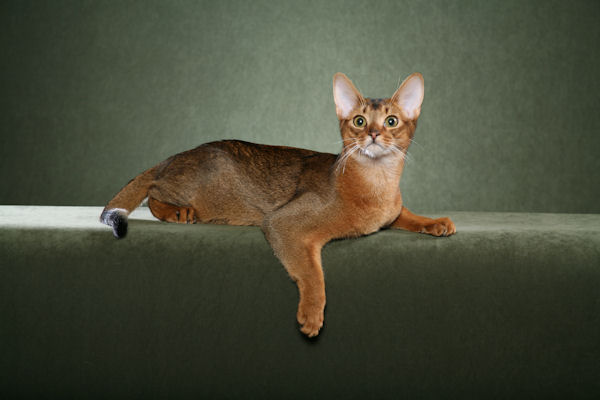

크기 조정 후: (224, 224)


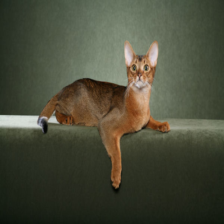

직접 조정 가로·세로 배율 0.3733 0.56
비율 유지 시 실제 사진 영역 (224, 149) 위·아래 여백 38 37


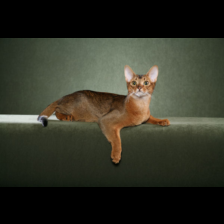

In [ ]:
# 1-1. 위 요구사항에 맞게 작성하세요.
# 여기에 코드를 작성하세요.

# ImageOps.contain으로 사각형 안에 맞추고 ImageOps.pad로 중앙에 여백을 더할 수 있습니다.
# ── 방법 1: 직접 Resize (비율 무시) ──
print("원본:", sample_row["image_path"], image.size)   # 준비 셀에서 읽은 첫 개발용 사진. size = (가로, 세로) → (600, 400)
display(image)                                         # 원본 사진 화면 표시
resized = transforms.Resize((224, 224))(image)
# 앞 괄호 Resize((224, 224))는 "224×224로 바꾸는 변환"을 만들고, 뒤 괄호 (image)가 그 변환을 사진에 실제 적용함
# 가로·세로를 각각 따로 224로 맞추므로 원래 비율(3:2)이 무너짐
print("크기 조정 후:", resized.size)                   # → (224, 224)
display(resized)

# ── 방법 2: 비율 유지 + 검은 여백 ──
target = (224, 224)                                    # 목표 크기 (가로, 세로)
content = ImageOps.contain(image, target, method=Image.Resampling.BILINEAR)
# contain: 가로·세로 비율을 유지한 채 224×224 상자 안에 들어가도록 줄임 → (224, 149)
# method=BILINEAR: 줄일 때 주변 픽셀 값을 섞어 새 픽셀 값을 계산하는 방식
padded = ImageOps.pad(image, target, method=Image.Resampling.BILINEAR, color="black")
# pad: contain과 같이 비율 유지로 줄인 뒤, 남는 칸을 검은색으로 채워 정확히 224×224로 만듦 (사진은 가운데)
top = round((target[1] - content.height) / 2)          # target[1] = 세로 224. 남는 높이 224-149 = 75를 반으로 → 위 여백 38
bottom = target[1] - content.height - top              # 나머지가 아래 여백 → 224 - 149 - 38 = 37
print("직접 조정 가로·세로 배율", round(224 / image.width, 4), round(224 / image.height, 4))
# → 가로 224/600 ≈ 0.3733배, 세로 224/400 = 0.56배. 두 배율이 달라 Resize 결과는 모양이 변형됨
print("비율 유지 시 실제 사진 영역", content.size, "위·아래 여백", top, bottom)  # → (224, 149), 38, 37
display(padded)

### 1-1. 정사각형 입력 두 개가 고양이를 다르게 보여주는 이유
### 원본 Abyssinian_1.jpg는 가로 600 x 세로 400입니다. 직접 Resize한 사진과 여백을 더한 사진은 모두 224 x 224이다. 고양이의 몸 비율과 사진 가장자리까지 함께 보존하는 조건에서는 여백을 추가한 결과를 선택한다.
|출력 순서|코드가 실제로 한 일|사진에서 확인할 부분|
|---|---|---|
|첫 번째 그림|image.size로 원본 가로, 세로를 읽고 display()|고양이가 가로로 긴 받침 위에 있고 몸통의 가로 길이와 아래로 내려온 다리를 기준으로 삼는다.|
|두 번째 그림|Resize((224,224))가 가로와 세로를 지정한 크기로 각각 바꿈|같은 고양이가 상대적으로 가늘고 길어 보이게 매치됨, 원본 장면은 화면에 들어 있지만 두 방향의 축소 비율이 다르다.|
|세 번쨰 그림|ImageOps.contain으로 비율을 유지했을 떄의 크기를 구하고, ImageOps.pad로 검은 바탕 한 가운데 배치|실제 사진은 가운데 가로 띠에 놓입니다. 받침과 고양이 몸의 원래 비율을 확인할 수 있다.|

### 계산식 이해하기
### 가로는 224 / 600 = 약 0.37배, 세로는 224 / 400 = 약 0.56배, 가로가 더 많이 줄었기 떄문에 Resize에서 형태가 변한다.
### 이 비율을 유지하기 위해서는 두 축에 같은 약 0.37을 적용해야 한다. 세로는 400 x 0.37 = 149픽셀
### 실제 출력 사진 영역은 224 x 149, 남은 높이는 224 - 149로 75픽셀을 의미한다.

In [ ]:
# 1-2. 위 요구사항에 맞게 작성하세요.
# 여기에 코드를 작성하세요.
tensor_01 = transforms.ToTensor()(resized)
# ToTensor: PIL 사진(세로, 가로, 채널, 0~255 정수) → 텐서(채널, 세로, 가로, 0~1 실수)
# 값은 255로 나눠 0~1로, 축은 PyTorch가 쓰는 (C, H, W) 순서로 바뀜. 변수 이름 _01 = 값 범위 0~1
normalizer = transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
# R·G·B 채널마다 (값 - 평균) / 표준편차 를 계산하는 변환을 준비 (아직 적용 전)
# 평균·표준편차를 사진에서 계산하는 게 아니라 0.5로 정해 준 값임
tensor_norm = normalizer(tensor_01)      # 실제 적용 → (x - 0.5) / 0.5 = 2x - 1 이므로 0~1 범위가 -1~1 범위로 바뀜
# ── 두 단계 결과를 같은 항목으로 출력 ──
for name, x in [("ToTensor 후", tensor_01), ("Normalize 후", tensor_norm)]:
    # (이름, 텐서) 쌍 2개를 차례로 꺼내 name, x에 담아 같은 출력을 반복함
    print(name, "shape=", tuple(x.shape), "dtype=", x.dtype,
          "min=", x.min().item(), "max=", x.max().item())
    # x.min()/x.max(): 세 채널 전체에서 가장 작은/큰 값. item()은 텐서에서 파이썬 숫자 하나로 꺼냄
# → 두 단계 모두 shape (3, 224, 224), float32. 값 범위만 약 0.004~0.925 → 약 -0.992~0.851 로 바뀜

ToTensor 후 shape= (3, 224, 224) dtype= torch.float32 min= 0.003921568859368563 max= 0.9254902005195618
Normalize 후 shape= (3, 224, 224) dtype= torch.float32 min= -0.9921568632125854 max= 0.8509804010391235


### 1-2. 0 ~ 1 변환과 평균, 표준편차 정규화를 단계별로 읽기
### 두 텐서 모두 (3, 224, 224)의 torch.float32입니다. 한 장에서 실제 관측된 최솟값, 최댓값은 ToTensor 후 약 0.003922와 0.925490, Normalize 후 약 -0.992157과 0.850980입니다.

### 1. transforms.ToTensor()(resized)에서 앞 괄호는 변환을 준비하고, 뒤 괄호는 그 변환을 실제 PIL 사진에 적용한다. 이번 8비트 RGB 입력에서는 픽셀 성분을 255로 나눠 실수로 바꾸고 축을(채널, 높이, 너비)로 놓는다.
### 2. Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])는 R,G,B 각각에서 뺄 값과 나눌 값을 지정한다. 사진 한 장의 평균과 표준편차를 이 줄에서 계산한 것은 아니다.
### 3. tensor_norm = normalizer(tensor_01)에서 수치가 바뀐다. 직사각형의 위치나 채널 수는 바뀌지 않으므로 shape도 그대로 이다. 반복문 전 / 후 텐서에서 같은 항목으로 출력하므로 값을 바로 비교할 수 있다.
### 4. x.min().item()은 세 채널의 모든 위치를 살펴 가장 작은 수 하나를 꺼낸다. 점 하나의 빨강 값을 읽는 다음 문항과 구분한다.

### 왜 최소값이 정확히 -1이 아닌가? -> 직접 Resize한 사진에서 가장 어두운 채널 값은 1 / 255 약 0.003922이고, 가장 큰 값은 26/ 255로 약 0.92이다. 이번 설정에서 정규화 식은 (x - 0.5) / 0.5 = 2x - 1이고 두 값을 대입 하면 각각 약 -0.99와 0.85가 된다. -1 ~ 1은 가능함 범위이고 -1과 1을 반드시 포함해야하는 것은 아니다.

In [ ]:
######################################### 요기서부터 해설하면 됨 ################################### 
# 1-3. 위 요구사항에 맞게 작성하세요. 
# 여기에 코드를 작성하세요.
before = tensor_01[0, 0, 0].item()       # [채널 0=R, 행 0, 열 0] → 맨 왼쪽 위 픽셀의 빨강 값(정규화 전). ≈ 0.1176 (= 30/255)
after = tensor_norm[0, 0, 0].item()      # 같은 위치의 정규화 후 값 ≈ -0.7647
calculated = (before - 0.5) / 0.5        # 교안 식 (픽셀 값 - 평균) / 표준편차 로 직접 계산
print("첫 R 값: 정규화 전=", before, "정규화 후=", after)
print("식으로 계산한 값:", calculated)
print("절댓값 차이:", abs(after - calculated))
# abs(): 부호를 뗀 차이. → 약 1.5e-08 (0.000000015)로 사실상 같음
# 아주 작은 차이는 텐서(float32)와 파이썬 실수(float64)의 저장 자릿수 차이 때문임
# ── 기준점 0, 0.5, 1이 정규화 후 어떤 값이 되는지 ──
for value in [0.0, 0.5, 1.0]:
    print(value, "→", (value - 0.5) / 0.5)  # → 0은 -1, 0.5는 0, 1은 1

첫 R 값: 정규화 전= 0.11764705926179886 정규화 후= -0.7647058963775635
식으로 계산한 값: -0.7647058814764023
절댓값 차이: 1.4901161193847656e-08
0.0 → -1.0
0.5 → 0.0
1.0 → 1.0


###### 요기서부터 해설하면 됨

**정답**　직접 Resize한 사진의 맨 왼쪽 위 빨강 성분은 30입니다. ToTensor 후 약 0.117647, Normalize 후 약 −0.764706입니다.

| 한 줄씩 따라가기 | 읽은 값 또는 계산 | 의미 |
|---|---:|---|
| tensor_01[0, 0, 0].item() | 30 ÷ 255 ≈ 0.117647 | 첫 0은 빨강, 둘째 0은 첫 행, 셋째 0은 첫 열입니다. item()은 그 자리에 있는 숫자 하나를 꺼냅니다. |
| before − 0.5 | 약 −0.382353 | 해당 픽셀이 기준인 0.5보다 어두운 쪽에 있습니다. |
| (before − 0.5) ÷ 0.5 | 약 −0.764706 | 교안에서 정한 기준으로 표현한 값입니다. 음수도 정상적인 모델 입력값입니다. |
| tensor_norm[0, 0, 0] | 약 −0.764706 | 같은 위치의 실제 출력과 수식 결과가 소수점 여섯 자리까지 일치합니다. |

**절댓값 차이 읽기**　약 1.49 × 10⁻⁸은 0.000000015 정도입니다. torch.float32로 처리한 값과 item()을 꺼내 Python에서 계산한 값은 유한한 자릿수로 저장되므로 마지막 자리에 작은 차이가 생길 수 있습니다. 비교할 때 사진이나 좌표를 바꿔 버리면 이 검산 자체가 성립하지 않습니다.

**세 기준점**　x가 0이면 (0 − 0.5) / 0.5 = −1, x가 0.5이면 0, x가 1이면 1입니다. 이 식은 0.5를 중심으로 어두운 쪽은 음수, 밝은 쪽은 양수로 표현합니다. 숫자 표현이 달라진 것이며 원래 픽셀의 색이 사라졌다는 뜻은 아닙니다.

### 1-4 Resize, Crop, Padding, 정규화를 언제 선택할 수 있을까?

**예시 답안**　동물의 위치와 형태를 다루는 연산과 채널 값을 다루는 연산을 따로 결정합니다. 예를 들어 수염 끝까지 남겨야 한다면 동물을 잘라 버릴 수 있는 영역 선택을 먼저 점검하고, 입력값의 범위는 이후 모델에 맞춰 확인합니다.

| 방법 | 이 사진에 적용할 때 얻는 것 | 함께 확인할 점 |
|---|---|---|
| 직접 Resize | 고양이와 받침을 포함한 전체 장면을 정사각형 안에 채움 | 가로 0.3733배, 세로 0.56배이므로 얼굴과 몸의 비율이 달라집니다. |
| 비율 유지 후 Crop | 남겨진 부분의 형태를 유지하면서 입력을 채움 | 잘린 방향의 가장자리 정보는 사라집니다. 대상의 귀나 꼬리가 경계에 있다면 실제 자른 영역을 확인해야 합니다. |
| 비율 유지 후 Padding | 전체 장면과 몸의 비율을 유지 | 224행 중 75행이 여백입니다. 같은 입력 크기에서 원래 사진에 할당되는 면적이 줄어듭니다. |
| Normalize | 이미 정해진 위치에서 각 색 성분의 수치 표현을 변경 | 가늘어진 얼굴이나 사라진 가장자리 정보는 정규화로 복구할 수 없습니다. |

**모델 입력 조건과 연결하기**　여기서 0.5와 0.5는 전·후 결과를 손으로 검산하기 위한 교안의 설정입니다. 다른 가중치가 채널마다 다른 평균·표준편차를 지정하면 같은 RGB 사진도 입력 수치가 달라집니다. 따라서 이번 실습에서 중요한 판단은 “무조건 0.5를 쓴다”가 아니라 “모델이 기대하는 기본 전처리 조건을 세트마다 일관되게 적용한다”입니다.

### 문항별 해석 작성

**1-1 답변:** (실제 출력의 의미와 요구된 설명을 작성하세요.)

**1-2 답변:** (실제 출력의 의미와 요구된 설명을 작성하세요.)

**1-3 답변:** (실제 출력의 의미와 요구된 설명을 작성하세요.)

**1-4 답변:** (실제 출력의 의미와 요구된 설명을 작성하세요.)

---
## 필수 2. 원본 이미지 분할과 데이터 누수 점검

**배경**  
ZIP에 실제로 존재하는 이미지로 학습용·선택용·최종 평가용 목록을 만들려고 합니다. 준비된 `pool_df`는 개발용 원본 736장, `official_test_df`는 유지할 공식 Test 목록입니다. 이미지를 증강하거나 파일을 옮기기 전에 **원본 목록부터 분할**하세요.

**요구사항**
1. **2-1:** `GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)`를 사용하여 `pool_df`를 Train·Validation으로 분할하세요. 그룹은 `image_id`로 지정하고 `iloc`로 행을 선택하세요. Test는 `official_test_df`를 사용하세요.
2. **2-2:** 각 세트의 이미지 수와 품종 수, 개발용 원본 안에서의 Train·Validation 비율을 출력하세요. 품종별 개수와 세트 내부 비율을 표로 비교하세요. Train과 Validation의 세트 내 비율 차이(퍼센트포인트)가 가장 큰 품종 한 개를 골라 두 비율과 장수를 인용하세요. 아래 제공된 집계 코드의 변수 이름을 연결해 사용해도 됩니다.
3. **2-3:** 세트 간 `image_id` 집합과 `image_path` 집합이 서로 겹치지 않는지 각각 확인하세요. 교안의 isdisjoint와 assert를 사용하세요. 다음으로 Train 첫 사진의 좌우 반전본을 메모리에서 만들고, 원본 ID는 같고 경로만 다른 행을 Validation의 점검용 사본에 추가하세요. Train과 이 사본 간에 경로 검사와 원본 ID 검사가 각각 무엇을 탐지하는지 출력하세요. 원래 세트는 보존하세요.
4. **2-4:** ① 각 세트의 역할 ② 이번 그룹의 의미 ③ 클래스 비율 유지 여부와 더 적합한 분할 개념 ④ 이미지 ID 중복 없음으로 확인할 수 없는 누수 ⑤ 증강보다 분할을 먼저 해야 하는 이유를 설명하세요.

**분포 집계용 제공 코드**
```python
count_table = pd.DataFrame({
    "Train": train_df["class_name"].value_counts(),
    "Validation": val_df["class_name"].value_counts(),
    "Test": test_df["class_name"].value_counts()
}).fillna(0).astype(int).sort_index()
ratio_table = count_table.div(count_table.sum(axis=0), axis=1).mul(100).round(2)
display(count_table)
display(ratio_table)
```

**제출 결과**: 분할 코드, 건수·비율 표, 중복 검사 결과, 누수 점검의 범위와 한계.

In [ ]:
# 2-1. 위 요구사항에 맞게 작성하세요.
# 여기에 코드를 작성하세요.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
# 그룹 단위로 섞어서 나누는 도구를 만듦
# n_splits=1: 한 번만 나눔 / test_size=0.2: 20%를 떼어 냄(여기서는 Validation) / random_state=42: 매번 같은 결과가 나오게 고정
train_idx, val_idx = next(splitter.split(pool_df, groups=pool_df["image_id"]))
# split(...)은 나눈 결과를 하나씩 내주는 생성기이고, next(...)로 첫 번째(유일한) 결과를 꺼냄
# 결과는 (Train 행 위치 배열, Validation 행 위치 배열) 두 개 → 두 변수에 나눠 담음
# groups=image_id: 같은 image_id를 가진 행은 반드시 같은 쪽으로 함께 보냄
train_df = pool_df.iloc[train_idx].copy()  # iloc[위치들]: 0부터 센 행 순번으로 행을 골라냄
val_df = pool_df.iloc[val_idx].copy()      # copy(): 원래 pool_df와 분리된 새 표로 만들어, 뒤 수정이 원본에 영향 없게 함
test_df = official_test_df.copy()          # Test는 새로 나누지 않고 공식 Test 목록을 그대로 사용
print("분할에 사용한 원본 수:", len(pool_df))  # len(표) = 행 수 → 736 (Train 588 + Validation 148)

분할에 사용한 원본 수: 736


### 2-1. 어떤 736장을 대상으로 588장과 148장을 만들었는가?

**정답**　공식 Test 3,669장을 먼저 따로 둡니다. 실제 파일이 있는 기존 val 736장을 개발용 원본으로 삼아 이번 실습의 Train 588장과 Validation 148장으로 다시 나눕니다. 메타데이터에 적힌 기존 train 2,944장은 이번 ZIP에 원본 JPEG가 없어 읽을 수 없습니다.

1. `GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)`는 그룹을 기준으로 한 번 분할할 방법을 만듭니다. 이때 test_size는 **현재 분할에서 떼어 놓을 쪽**의 비율입니다. 이 코드가 받는 데이터는 pool_df뿐이므로 떼어 놓은 쪽은 이번 수업의 Validation입니다. 이미 따로 둔 공식 Test에서 20%를 뽑는 명령이 아닙니다.
2. `splitter.split(pool_df, groups=pool_df["image_id"])`에 원본 ID를 넘깁니다. 같은 ID에 속한 행들을 하나의 묶음으로 다루게 됩니다. 이번의 깨끗한 원본 목록에는 ID당 한 행씩 있으므로 그룹 수와 사진 수가 같습니다.
3. `next(...)`가 첫 분할의 두 위치 목록을 돌려줍니다. `pool_df.iloc[train_idx]`는 Train으로 배정된 위치들의 행을 꺼냅니다. 여기서 위치는 테이블의 순번이고 사진을 식별하는 image_id와는 별개입니다. copy()를 붙여 뒤에서 작업할 표를 원래 목록과 구분합니다.
4. `test_df = official_test_df.copy()`는 공식 Test의 소속을 유지합니다. 사진을 실제로 이동하거나 파일명을 바꿀 필요가 없습니다. Train 사진의 경로에 여전히 images/val이 들어 있는 이유입니다.

**검산**　588 + 148 = 736이고, 여기에 별도로 둔 3,669장을 더하면 4,405장입니다. 정수 장수로 나눠야 하므로 736 × 0.2 = 147.2장에 정확히 맞출 수 없습니다. 다음 출력에서 실제 비율을 다시 계산합니다.

In [ ]:
# 2-2. 위 요구사항에 맞게 작성하세요.
# 여기에 코드를 작성하세요.
# ── 세트별 이미지 수·품종 수와 분할 비율 ──
for name, data in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    # (이름, 표) 쌍을 하나씩 꺼내 같은 출력을 세 세트에 반복함
    print(name, "이미지 수=", len(data), "품종 수=", data["class_name"].nunique())
    # nunique(): 서로 다른 값의 개수 → 같은 품종이 여러 장이어도 한 번만 셈
print("개발용 원본 중 Train 비율:", round(len(train_df) / len(pool_df) * 100, 2), "%")       # 588/736 → 79.89 %
print("개발용 원본 중 Validation 비율:", round(len(val_df) / len(pool_df) * 100, 2), "%")    # 148/736 → 20.11 %

# ── 품종별 장수 표와 세트 내부 비율 표 ──
count_table = pd.DataFrame({
    "Train": train_df["class_name"].value_counts(),       # value_counts(): 품종 이름별 장수를 셈
    "Validation": val_df["class_name"].value_counts(),
    "Test": test_df["class_name"].value_counts()
}).fillna(0).astype(int).sort_index()
# 세 결과를 열로 붙이면 품종 이름(행 이름)을 기준으로 줄이 맞춰짐
# fillna(0): 어떤 세트에 없는 품종은 빈칸(NaN) → 0으로 채움
# astype(int): NaN 때문에 실수가 된 값을 정수로 / sort_index(): 품종 이름 알파벳순 정렬
ratio_table = count_table.div(count_table.sum(axis=0), axis=1).mul(100).round(2)
# sum(axis=0): 위아래로 더함 → 열(세트)마다 전체 장수 (588, 148, 3669)
# div(..., axis=1): 각 열을 그 열 이름에 맞는 합계로 나눔 → 세트 안에서의 비율
# mul(100): 100을 곱해 % 로 / round(2): 소수 둘째 자리까지 반올림
print("품종별 이미지 수")
display(count_table)
print("각 세트 안에서 품종별 비율(%)")
display(ratio_table)

# ── Train과 Validation 비율 차이가 가장 큰 품종 찾기 ──
shares = count_table.div(count_table.sum(), axis="columns") * 100
# ratio_table과 같은 계산이지만 반올림하지 않은 값. sum()의 기본은 axis=0, axis="columns"는 axis=1과 같은 뜻
gap = (shares["Train"] - shares["Validation"]).abs()  # 품종마다 두 비율의 차이, abs()로 부호를 없앰 → %p 단위
breed = gap.idxmax()                     # idxmax(): 값이 가장 큰 행의 이름(품종)을 돌려줌 → Bombay
print("차이가 가장 큰 품종", breed)
print("Train / Validation 장수", count_table.loc[breed, ["Train", "Validation"]].tolist())
# loc[행 이름, 열 이름 목록]: 이름으로 칸을 골라냄 → Bombay 행의 Train·Validation 값 → [9, 10]
print("Train / Validation 비율(%)", shares.loc[breed, ["Train", "Validation"]].round(2).tolist())  # → [1.53, 6.76]
print("차이(%p)", round(gap.loc[breed], 2))  # → 5.23 %p

Train 이미지 수= 588 품종 수= 37
Validation 이미지 수= 148 품종 수= 37
Test 이미지 수= 3669 품종 수= 37
개발용 원본 중 Train 비율: 79.89 %
개발용 원본 중 Validation 비율: 20.11 %
품종별 이미지 수


,Train,Validation,Test
class_name,,,
Abyssinian,18,2,98
Bengal,15,5,100
Birman,16,4,100
Bombay,9,10,88
British_Shorthair,14,6,100
Egyptian_Mau,17,2,97
Maine_Coon,16,4,100
Persian,18,2,100
Ragdoll,17,3,100


각 세트 안에서 품종별 비율(%)


,Train,Validation,Test
class_name,,,
Abyssinian,3.06,1.35,2.67
Bengal,2.55,3.38,2.73
Birman,2.72,2.70,2.73
Bombay,1.53,6.76,2.40
British_Shorthair,2.38,4.05,2.73
Egyptian_Mau,2.89,1.35,2.64
Maine_Coon,2.72,2.70,2.73
Persian,3.06,1.35,2.73
Ragdoll,2.89,2.03,2.73


차이가 가장 큰 품종 Bombay
Train / Validation 장수 [9, 10]
Train / Validation 비율(%) [1.53, 6.76]
차이(%p) 5.23


### 2-2. 전체 분할 비율과 품종별 구성비를 구분하기

**정답**　개발용 사진 중 Train은 588/736 = 79.89%, Validation은 148/736 = 20.11%입니다. Train·Validation·Test에는 각각 37품종이 있습니다. 그러나 품종 수가 같아도 각 품종의 비중은 다릅니다. 차이가 가장 큰 예는 Bombay입니다.

**표 만드는 코드 읽기**

- `len(data)`는 사진 행 수, `data["class_name"].nunique()`는 서로 다른 품종 이름 수입니다. 같은 품종 사진이 열 장 있어도 후자에서는 한 번만 셉니다.
- `value_counts()`를 각 세트에 적용하면 품종별 장수가 나옵니다. 세 결과를 열로 합칠 때 품종 이름이 행을 맞추는 기준입니다. 한 세트에 없는 품종이라면 fillna(0)로 그 세트의 장수를 0으로 표시합니다.
- `count_table.div(count_table.sum(axis=0), axis=1)`는 각 열을 그 열의 전체 장수로 나눕니다. axis=0으로 열별 합계를 구한 뒤, axis=1로 Train·Validation·Test라는 열 이름에 각각의 분모를 맞춥니다. 100을 곱하면 세트 내부의 백분율입니다.
- `gap.idxmax()`는 반올림 전 두 비율의 절대 차이가 가장 큰 품종 이름을 반환합니다. 이 이름으로 장수 표와 비율 표의 같은 행을 봅니다.

| Bombay를 기준으로 묻는 질문 | 계산 | 결과가 뜻하는 것 |
|---|---|---|
| Train 안에서 몇 %인가? | 9 ÷ 588 × 100 | 약 1.53%. Train 100장 중 약 1.5장에 해당하는 비중입니다. |
| Validation 안에서는 몇 %인가? | 10 ÷ 148 × 100 | 약 6.76%. Validation의 분모가 작아 한 장의 영향이 더 큽니다. |
| 두 구성비는 얼마나 다른가? | 두 비율의 차이의 절댓값 | 약 5.23%p. 퍼센트포인트는 이미 백분율로 표현한 두 수의 차이입니다. |

**판단**　9장과 10장은 장수로는 한 장 차이입니다. 하지만 세트의 크기가 달라 비중은 크게 다릅니다. “37품종이 모두 있다”는 점검은 누락 품종이 없다는 뜻이고, 비율이 고르게 유지됐다는 보장은 아닙니다.

In [ ]:
# 2-3. 위 요구사항에 맞게 작성하세요.
# 여기에 코드를 작성하세요.
# ── 원래 분할에서 세트 간 중복 검사 ──
for column in ["image_id", "image_path"]:  # 원본 ID 기준과 파일 경로 기준으로 한 번씩 검사
    train_ids = set(train_df[column])      # set(): 열의 값들을 중복 없는 집합으로 만듦
    val_ids = set(val_df[column])
    test_ids = set(test_df[column])
    print(column, "Train/Validation:", train_ids.isdisjoint(val_ids),
          "Train/Test:", train_ids.isdisjoint(test_ids),
          "Validation/Test:", val_ids.isdisjoint(test_ids))
    # isdisjoint(): 두 집합에 공통 원소가 하나도 없으면 True (= 겹치지 않음)
    assert train_ids.isdisjoint(val_ids)   # assert 조건: 조건이 False면 그 자리에서 오류를 내고 멈춤
    assert train_ids.isdisjoint(test_ids)  # → 겹침이 있으면 다음 단계로 넘어가지 못하게 막는 안전장치
    assert val_ids.isdisjoint(test_ids)
assert len(train_df) + len(val_df) == len(pool_df)  # 588 + 148 = 736 → 나누는 중 빠지거나 늘어난 행이 없는지 확인
print("이미지 ID와 경로의 세트 간 중복 없음 / 개발용 원본 건수 보존")

# ── 반전본을 Validation 점검용 사본에 넣어 보기 ──
origin = train_df.iloc[0]                # Train의 첫 행 (한 행 = Series). image_id는 Abyssinian_1
flipped = ImageOps.mirror(load_rgb(origin["image_path"]))  # 실제 사진을 읽어 좌우 반전본을 메모리에만 만듦 (파일 저장 안 함)
probe = origin.copy()                    # 원래 행을 바꾸지 않도록 복사본을 만듦
probe["image_path"] = "memory://" + str(origin["image_id"]) + "_flip.jpg"
# 경로만 새 이름으로 바꿈 → image_id는 원본과 같고 image_path만 다른 행이 됨
val_probe = pd.concat([val_df, probe.to_frame().T], ignore_index=True)
# to_frame().T: 한 행(Series)을 한 줄짜리 표(DataFrame)로 바꿈 (.T는 행과 열을 뒤집기)
# concat: 두 표를 위아래로 이어 붙임. ignore_index=True는 행 번호를 0부터 새로 매김
# 원래 val_df는 그대로 두고, 점검용 새 표 val_probe만 만듦
print("진단용 반전본", flipped.size, probe["image_path"])
for key in ["image_path", "image_id"]:
    overlap = set(train_df[key]) & set(val_probe[key])  # & : 두 집합 모두에 있는 값만 남김(교집합)
    print(key, "교집합 수", len(overlap), "중복값", sorted(overlap))  # sorted(): 정렬된 리스트로 출력
# → 경로 기준 교집합 0개(누수 못 찾음), ID 기준 1개 ['Abyssinian_1'](누수 찾음)
print("원래 Validation / 진단용 사본", len(val_df), len(val_probe))  # → 148, 149 (원래 세트는 보존됨)

image_id Train/Validation: True Train/Test: True Validation/Test: True
image_path Train/Validation: True Train/Test: True Validation/Test: True
이미지 ID와 경로의 세트 간 중복 없음 / 개발용 원본 건수 보존
진단용 반전본 (600, 400) memory://Abyssinian_1_flip.jpg
image_path 교집합 수 0 중복값 []
image_id 교집합 수 1 중복값 ['Abyssinian_1']
원래 Validation / 진단용 사본 148 149


### 2-3. 경로가 모두 다른데도 원본 누수가 생기는 상황

**정답**　원래 분할은 원본 ID와 경로 모두에서 세트 간 교집합이 비어 있습니다. Train 사진 한 장의 좌우 반전본을 Validation 점검용 사본에 넣자 경로 교집합은 0개지만 원본 ID 교집합은 1개(Abyssinian_1)가 됐습니다.

**먼저 원래 목록을 검사합니다.** `set(train_df[column])`은 한 열의 값을 집합으로 만듭니다. `isdisjoint`가 True이면 양쪽에 공통 원소가 없다는 뜻입니다. 열 2개에 대해 Train–Validation, Train–Test, Validation–Test 세 쌍을 확인하므로 총 여섯 결과가 True입니다. assert는 조건이 깨지면 그 자리에서 실행을 멈춥니다. 588 + 148 = 736이라는 건수 검사만으로는 두 목록에 같은 원본이 들어간 상황을 찾아낼 수 없어 교집합 검사도 필요합니다.

**한 행을 따라가며 검사 방법을 시험합니다.**

| 단계 | 파일 또는 표에서 일어난 일 | 판단에 쓰는 정보 |
|---|---|---|
| origin을 선택 | Train 첫 원본은 Abyssinian_1.jpg | image_id는 Abyssinian_1입니다. |
| ImageOps.mirror로 뒤집기 | 실제 원본을 읽어 600 × 400 좌우 반전본을 메모리에 만듦 | 좌우 방향은 달라져도 같은 원본에서 나온 사진입니다. |
| probe의 경로만 변경 | memory://Abyssinian_1_flip.jpg라는 점검용 이름을 부여 | 별도 JPEG를 저장하지 않습니다. 원본 ID는 그대로 둡니다. |
| val_probe에 한 행 추가 | 기존 Validation 148행, 점검용 사본 149행 | 진단용 행은 실제 Validation이나 뒤의 전처리 과제에 들어가지 않습니다. |

**검사 결과를 읽는 법**　`set(train_df[key]) & set(val_probe[key])`에서 &는 양쪽에 있는 값만 남깁니다. 경로로 보면 원본명과 반전본 이름이 달라 []입니다. ID로 보면 두 행이 같은 원본을 가리켜 ['Abyssinian_1']입니다. 평가 세트에서 이미 학습에 쓰인 장면을 다시 보게 되는 위험을 잡으려면 변환 뒤의 파일명뿐 아니라 변환 전 원본의 소속을 추적해야 합니다.

### 2-4. 무엇을 기준으로 나누고, 어디까지 누수를 점검했는가?

**예시 답안**　먼저 원본을 세트에 배정하고 해당 원본에서 파생한 증강 입력은 같은 세트 안에서만 사용합니다. 그룹을 정할 때에는 어떤 중복을 막으려는지 먼저 정합니다.

1. **세트의 역할**　Train은 모델이 예시를 보며 파라미터를 학습하는 데, Validation은 학습 도중 설정을 선택하는 데, Test는 선택이 끝난 뒤 최종 성능을 평가하는 데 사용합니다. 이번 강의는 이 역할에 맞게 입력을 준비하는 단계입니다.
2. **그룹의 단위**　Abyssinian_1은 사진 한 장의 식별자이고 Abyssinian은 품종입니다. 사진 한 장을 여러 버전으로 만든 경우에는 원본 ID로 묶을 수 있습니다. 그러나 같은 고양이를 다른 날짜에 찍은 사진은 서로 다른 image_id일 수 있습니다. 동일 동물의 분리까지 검증하려면 동물 개체를 연결하는 식별 정보가 필요합니다.
3. **그룹과 품종 비율**　그룹 분할은 같은 그룹이 갈라지는 것을 막습니다. 품종 비중까지 일정하게 만드는 조건은 들어 있지 않습니다. 비율 유지가 목표라면 교안의 층화 분할 개념을 검토합니다. 파생본이나 같은 개체의 묶음도 있다면 비율을 맞추는 과정에서도 그 묶음을 지켜야 합니다.
4. **이번 근거의 범위**　2-3의 True는 제공된 ID와 경로에서 교집합을 발견하지 못했다는 근거입니다. 서로 다른 이름으로 저장한 똑같은 사진이나 같은 개체의 다른 촬영본까지 찾았다는 뜻은 아닙니다.
5. **순서**　반전본부터 만들어 원본과 독립된 행처럼 무작위 분할하면 2-3의 점검 사례가 실제로 생길 수 있습니다. 원본의 세트를 정한 뒤 Train 내부에서만 증강하면 우연한 행 배정 때문에 원본과 파생본이 갈라질 가능성을 줄일 수 있습니다.

### 문항별 해석 작성

**2-1 답변:** (실제 출력의 의미와 요구된 설명을 작성하세요.)

**2-2 답변:** (실제 출력의 의미와 요구된 설명을 작성하세요.)

**2-3 답변:** (실제 출력의 의미와 요구된 설명을 작성하세요.)

**2-4 답변:** (실제 출력의 의미와 요구된 설명을 작성하세요.)

---
## 과제 1. 학습용·평가용 전처리 파이프라인 구성 — 필수 수준

**배경**  
동물의 품종을 분류하기 위한 입력 데이터를 준비합니다. 촬영 방향과 조명의 차이를 학습 데이터에 반영하되 평가 입력은 일정하게 유지하려고 합니다. **실습 준비 셀만 실행한 상태에서도 수행할 수 있도록**, `pool_df`, `official_test_df`, `load_rgb`, `show_normalized`에서 시작하세요. 필수 문제의 정답 변수는 사용하지 않습니다.

**요구사항**
1. **3-1:** 필수 2와 같은 설정의 `GroupShuffleSplit`으로 `pool_df`를 다시 분할하여 `task_train_df`, `task_val_df`를 만드세요. `Compose`로 아래 두 파이프라인을 구성하고 출력하세요.
   - Train: `Resize((224,224)) → RandomHorizontalFlip(p=0.5) → ColorJitter(brightness=0.2) → ToTensor → Normalize(mean=0.5 세 개, std=0.5 세 개)`
   - Validation/Test: 같은 Resize·ToTensor·Normalize만 적용
2. **3-2:** 제공 함수 sample_rows로 각 세트에서 12장을 고르세요. 실제 JPEG를 읽어 Train에는 학습용, Validation·Test에는 평가용 변환을 적용하고 세트별 배치를 만드세요. 36장 전체의 입력 조건을 확인하고, 세트별 첫 파일·품종·배치 shape·dtype·값 범위를 출력하세요. Train 첫 원본과 그 증강 결과를 이미지로 표시하세요.
3. **3-3:** 같은 원본, 같은 순서로 변환을 한 번 더 실행하세요. 세트별로 두 번의 출력이 모든 원소에서 정확히 같은 사진 수를 세세요. 추가로 같은 Validation 12장에 학습용 변환을 두 번 적용한 대조 실험을 수행하고, 평가용 변환 결과와 비교해 운영할 파이프라인을 선택하세요.
4. **3-4:** 세트별로 공유하는 설정과 Train에만 두는 연산을 설명하세요. 품종 라벨의 보존, 실제 화면, 반복 비교 결과를 근거로 증강 선택을 설명하고 성능 향상을 판단하려면 필요한 근거를 쓰세요.

**재현 조건**　3-2의 첫 변환 직전에 torch.manual_seed(42)를 한 번 실행합니다. 이후에는 같은 난수 흐름을 이어갑니다. Test는 입력 규격·재현성 확인에만 사용합니다.

**제출 결과**　두 파이프라인, 36장의 배치 검사 결과, 원본·증강 비교 이미지, 반복 비교표와 문항별 해석.

In [ ]:
# 3-1. 위 요구사항에 맞게 작성하세요.
# 여기에 코드를 작성하세요.

In [ ]:
# 3-2. 위 요구사항에 맞게 작성하세요.
# 여기에 코드를 작성하세요.

# 이미지 목록에는 sample_rows(frame)["image_path"]를 사용하세요. torch.stack은 사진 축을 만듭니다.

In [ ]:
# 3-3. 위 요구사항에 맞게 작성하세요.
# 여기에 코드를 작성하세요.

# 같은 순서의 배치에서 사진을 한 장씩 짝지어 torch.equal로 비교하세요.

### 문항별 해석 작성

**3-1 답변:** (실제 출력의 의미와 요구된 설명을 작성하세요.)

**3-2 답변:** (실제 출력의 의미와 요구된 설명을 작성하세요.)

**3-3 답변:** (실제 출력의 의미와 요구된 설명을 작성하세요.)

**3-4 답변:** (실제 출력의 의미와 요구된 설명을 작성하세요.)

---
## 실습 마무리
다음 질문에 **이번에 출력한 실제 값과 이미지**를 근거로 답하세요.

**1. 어떤 문제가 있었는가?**　메타데이터 7,349행 중 2,944행에는 이번 ZIP에서 읽을 JPEG가 없었습니다. 또한 파일명이 달라지면 같은 장면의 반전본도 경로로는 다른 자료처럼 보였습니다. 평가 단계에서는 같은 Validation 사진에도 무작위 밝기·방향 변환을 적용하면 입력이 달라질 수 있었습니다.

**2. 어떻게 개선했는가?**　메타데이터 행마다 파일 존재 여부를 확인하고, 남은 개발용 원본을 먼저 분할했습니다. 파생본을 만들 때는 원본 ID를 유지하도록 했습니다. 실제 입력에는 Train에만 무작위 증강을 두고, Validation·Test에는 고정된 변환을 적용했습니다.

| 판단하려는 내용 | 내가 확인한 결과 | 여기서 내릴 수 있는 결론 |
|---|---|---|
| 데이터가 실제로 준비됐는가? | 7,349 − 2,944 = 4,405. 개발용 588 + 148 = 736, 별도 Test 3,669 | 이번 수업의 목록이 실제 파일 및 분할 건수와 맞습니다. |
| 같은 원본을 경로만으로 잡을 수 있는가? | 점검용 반전본을 넣자 공통 경로 0개, 공통 ID 1개 | 파일명 변경만으로 누수를 피할 수 없습니다. 변환 전 ID와 소속을 유지해야 합니다. |
| 분할 후 클래스 비율도 같아졌는가? | Bombay 비율 Train 1.53%, Validation 6.76% | 두 세트 모두 37품종이 있어도 비율은 차이가 납니다. |
| 모델에 전달할 기본 입력이 준비됐는가? | 36/36장 형태·자료형·범위 통과, 평가 변환 반복 시 Validation과 Test 각각 12/12장 동일 | 선택한 표본에서 입력 규격과 평가 재현성을 확인했습니다. |

**3. 무엇을 근거로 개선되었다고 판단했는가?**　같은 Validation 12장에 학습용 처리를 적용한 대조 실험은 두 실행의 완전 일치가 0장이었고, 평가용 처리에서는 12장이었습니다. 따라서 바뀐 점을 “평가 입력을 동일하게 재현할 수 있게 됐다”고 쓸 수 있습니다. 이번에 비교한 대상은 텐서와 원본 ID입니다. 품종 예측 정확도나 동일 동물의 다른 촬영본까지 분리됐는지는 이 결과만으로 판단할 수 없습니다.